<a href="https://colab.research.google.com/github/nicolasrporto/R-Applications/blob/main/TCD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
install.packages('caret')
install.packages("skimr")
library(skimr)
library(caret)
install.packages('C50', repos='cran.us.r-project.org')
install.packages("randomForest", dependencies = T)
library(C50)
library(randomForest)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘listenv’, ‘parallelly’, ‘future’, ‘globals’, ‘shape’, ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘diagram’, ‘lava’, ‘prodlim’, ‘proxy’, ‘iterators’, ‘Rcpp’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘timeDate’, ‘e1071’, ‘foreach’, ‘ModelMetrics’, ‘plyr’, ‘pROC’, ‘recipes’, ‘reshape2’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loading required package: ggplot2

Loading required package: lattice

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘libcoin’, ‘mvtnorm’, ‘Formula’, ‘inum’, ‘Cubist’, ‘partykit’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

randomForest 4.7-1.1

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:ggplot2’:

    ma

In [ ]:
dados = read.csv('nasa_asteroids.csv', header=TRUE)
head(dados)

dim(dados)

,Neo.Reference.ID,Name,Absolute.Magnitude,Est.Dia.in.KM.min.,Est.Dia.in.KM.max.,Est.Dia.in.M.min.,Est.Dia.in.M.max.,Est.Dia.in.Miles.min.,Est.Dia.in.Miles.max.,Est.Dia.in.Feet.min.,⋯,Asc.Node.Longitude,Orbital.Period,Perihelion.Distance,Perihelion.Arg,Aphelion.Dist,Perihelion.Time,Mean.Anomaly,Mean.Motion,Equinox,Hazardous
,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
1,3703080,3703080,21.6,0.127219878,0.28447230,127.219879,284.47230,0.079050743,0.1767628,417.3881,⋯,314.37391,609.5998,0.8082589,57.25747,2.005764,2458162,264.83753,0.5905514,J2000,True
2,3723955,3723955,21.3,0.146067964,0.32661790,146.067964,326.61790,0.090762397,0.2029509,479.2256,⋯,136.71724,425.8693,0.7181996,313.09197,1.497352,2457795,173.74111,0.8453298,J2000,False
3,2446862,2446862,20.3,0.231502122,0.51765448,231.502122,517.65448,0.143848705,0.3216555,759.5214,⋯,259.47598,643.5802,0.9507910,248.41504,1.966857,2458120,292.89365,0.5593708,J2000,True
4,3092506,3092506,27.4,0.008801465,0.01968067,8.801465,19.68067,0.005468975,0.0122290,28.8762,⋯,57.17327,514.0821,0.9839016,18.70770,1.527904,2457902,68.74101,0.7002772,J2000,False
5,3514799,3514799,21.6,0.127219878,0.28447230,127.219879,284.47230,0.079050743,0.1767628,417.3881,⋯,84.62931,495.5978,0.9676866,158.26360,1.483543,2457814,135.14213,0.7263954,J2000,True
6,3671135,3671135,19.6,0.319561887,0.71456210,319.561887,714.56210,0.198566489,0.4440082,1048.4314,⋯,178.97195,556.1606,0.5777998,198.14597,2.069265,2458009,354.23737,0.6472951,J2000,False


[1] 4687   40

In [ ]:
#quais parâmetros são importantes para a classificação hazardous ou não?

#Para fazer esse procedimento de forma mais objetiva faça uma análise de correlação entre as variáveis e, entre as que tiverem
#coeficiente de correlação 1, mantenha apenas uma delas. Remova da análise



#tirando nome, ID, estimativa de diâmetro em km, estimativa de diâmetro em milhas, estimativa de diâmetro em pés e variáveis com correlação 1
# tirar velocidade em milhas, pés, km/h, Orbit ID, Orbiting Body (?), Equinox, Hazardous (?)

#dadosfisicos <- data.frame(Absolute.Magnitude = dados$Absolute.Magnitude , Est.Dia.in.KM.min = dados$Est.Dia.in.KM.min. , Est.Dia.in.KM.max. = dados$Est.Dia.in.KM.max., Close.Approach.Date = dados$Close.Approach.Date, Epoch.Date.Close.Approach= dados$Epoch.Date.Close.Approach , Relative.Velocity.km.per.sec=dados$Relative.Velocity.km.per.sec , Miss.Dist..kilometers. = dados$Miss.Dist..kilometers., Orbit.Determination.Date=dados$Orbit.Determination.Date, Orbit.Uncertainity=dados$Orbit.Uncertainity, Minimum.Orbit.Intersection = dados$Minimum.Orbit.Intersection, Jupiter.Tisserand.Invariant= dados$Jupiter.Tisserand.Invariant, Epoch.Osculation = dados$Epoch.Osculation, Eccentricity = dados$Eccentricity, Semi.Major.Axis = dados$Semi.Major.Axis, Inclination = dados$Inclination, Asc.Node.Longitude = dados$Asc.Node.Longitude, Orbital.Period = dados$Orbital.Period, Perihelion.Distance = dados$Perihelion.Distance, Perihelion.Arg = dados$Perihelion.Arg, Aphelion.Dist = dados$Aphelion.Dist, Perihelion.Time = dados$Perihelion.Time, Mean.Anomaly = dados$Mean.Anomaly, Mean.Motion = dados$Mean.Motion)

dadosfisicos <- data.frame(Absolute.Magnitude = dados$Absolute.Magnitude , Est.Dia.in.KM.min = dados$Est.Dia.in.KM.min. , Est.Dia.in.KM.max. = dados$Est.Dia.in.KM.max., Relative.Velocity.km.per.sec=dados$Relative.Velocity.km.per.sec , Miss.Dist..kilometers. = dados$Miss.Dist..kilometers., Orbit.Uncertainity=dados$Orbit.Uncertainity, Minimum.Orbit.Intersection = dados$Minimum.Orbit.Intersection, Jupiter.Tisserand.Invariant= dados$Jupiter.Tisserand.Invariant, Epoch.Osculation = dados$Epoch.Osculation, Eccentricity = dados$Eccentricity, Semi.Major.Axis = dados$Semi.Major.Axis, Inclination = dados$Inclination, Asc.Node.Longitude = dados$Asc.Node.Longitude, Orbital.Period = dados$Orbital.Period, Perihelion.Distance = dados$Perihelion.Distance, Perihelion.Arg = dados$Perihelion.Arg, Aphelion.Dist = dados$Aphelion.Dist, Perihelion.Time = dados$Perihelion.Time, Mean.Anomaly = dados$Mean.Anomaly, Mean.Motion = dados$Mean.Motion)


head(dadosfisicos)


matriz_correlacao = cor(dadosfisicos)

#Exibir a matriz de correlação
print(matriz_correlacao)






,Absolute.Magnitude,Est.Dia.in.KM.min,Est.Dia.in.KM.max.,Relative.Velocity.km.per.sec,Miss.Dist..kilometers.,Orbit.Uncertainity,Minimum.Orbit.Intersection,Jupiter.Tisserand.Invariant,Epoch.Osculation,Eccentricity,Semi.Major.Axis,Inclination,Asc.Node.Longitude,Orbital.Period,Perihelion.Distance,Perihelion.Arg,Aphelion.Dist,Perihelion.Time,Mean.Anomaly,Mean.Motion
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,21.6,0.127219878,0.28447230,6.115834,62753692,5,0.0252819,4.634,2458000,0.4255491,1.407011,6.025981,314.37391,609.5998,0.8082589,57.25747,2.005764,2458162,264.83753,0.5905514
2,21.3,0.146067964,0.32661790,18.113985,57298148,3,0.1869350,5.457,2458000,0.3516743,1.107776,28.412996,136.71724,425.8693,0.7181996,313.09197,1.497352,2457795,173.74111,0.8453298
3,20.3,0.231502122,0.51765448,7.590711,7622912,0,0.0430579,4.557,2458000,0.3482483,1.458824,4.237961,259.47598,643.5802,0.9507910,248.41504,1.966857,2458120,292.89365,0.5593708
4,27.4,0.008801465,0.01968067,11.173874,42683616,6,0.0055118,5.093,2458000,0.2165783,1.255903,7.905894,57.17327,514.0821,0.9839016,18.70770,1.527904,2457902,68.74101,0.7002772
5,21.6,0.127219878,0.28447230,9.840831,61010824,1,0.0347980,5.154,2458000,0.2104479,1.225615,16.793382,84.62931,495.5978,0.9676866,158.26360,1.483543,2457814,135.14213,0.7263954
6,19.6,0.319561887,0.71456210,10.808844,58759768,1,0.2722130,4.724,2458000,0.5634411,1.323532,17.927751,178.97195,556.1606,0.5777998,198.14597,2.069265,2458009,354.23737,0.6472951


                             Absolute.Magnitude Est.Dia.in.KM.min
Absolute.Magnitude                   1.00000000       -0.61348151
Est.Dia.in.KM.min                   -0.61348151        1.00000000
Est.Dia.in.KM.max.                  -0.61348151        1.00000000
Relative.Velocity.km.per.sec        -0.37685294        0.24214075
Miss.Dist..kilometers.              -0.33911748        0.18802744
Orbit.Uncertainity                   0.67776385       -0.39948755
Minimum.Orbit.Intersection          -0.48823464        0.25790407
Jupiter.Tisserand.Invariant          0.23870159       -0.13358219
Epoch.Osculation                    -0.11608717        0.06158243
Eccentricity                        -0.36135944        0.21662288
Semi.Major.Axis                     -0.21243669        0.12122353
Inclination                         -0.45963151        0.25944997
Asc.Node.Longitude                  -0.01147006        0.03655826
Orbital.Period                      -0.20677436        0.11831372
Perihelion

In [ ]:

parametros <- data.frame(Absolute.Magnitude = dados$Absolute.Magnitude, Est.Dia.in.KM.max. = dados$Est.Dia.in.KM.max., Relative.Velocity.km.per.sec=dados$Relative.Velocity.km.per.sec , Miss.Dist..kilometers. = dados$Miss.Dist..kilometers., Orbit.Uncertainity=dados$Orbit.Uncertainity, Minimum.Orbit.Intersection = dados$Minimum.Orbit.Intersection, Jupiter.Tisserand.Invariant= dados$Jupiter.Tisserand.Invariant, Epoch.Osculation = dados$Epoch.Osculation, Eccentricity = dados$Eccentricity, Semi.Major.Axis = dados$Semi.Major.Axis, Inclination = dados$Inclination, Asc.Node.Longitude = dados$Asc.Node.Longitude, Orbital.Period = dados$Orbital.Period, Perihelion.Distance = dados$Perihelion.Distance, Perihelion.Arg = dados$Perihelion.Arg, Aphelion.Dist = dados$Aphelion.Dist, Perihelion.Time = dados$Perihelion.Time, Mean.Anomaly = dados$Mean.Anomaly, Mean.Motion = dados$Mean.Motion)


#defina as classes (hazardous TRUE = 1 e hazardous FALSE = 0)

hazardous = dados$Hazardous

hazardous_binario = c()

for (i in 1:length(hazardous)){
  if (hazardous[i] == "True") {
    classe = 1
    hazardous_binario = c(hazardous_binario, classe)

  } else {
    classe = 0
    hazardous_binario = c(hazardous_binario, classe)

  }


}

length(hazardous_binario)


[1] 4687

In [ ]:
# pré-processamento: normalização dos parâmetros entre 0 e 1


# valores máximos e mínimos de cada banda
maxs <- apply(parametros, 2, max)
mins <- apply(parametros, 2, min)
# reescalonamento usando a função scale():
parametros_norm  <- as.data.frame(scale(parametros, center = mins, scale = maxs - mins))

# exemplo de dados normalizados
summary(parametros_norm[,2])

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.000000 0.002083 0.007048 0.013069 0.016229 1.000000 

In [ ]:
#Crie conjuntos de treinamento e teste

set.seed(1132768)

dadosfinal = parametros

#ou parametros_norm?

dadosfinal$classe =  hazardous_binario


#vamos considerar 75% dos objetos para treinamento e 25% para teste


ntreino = round(0.75*nrow(dadosfinal))
nteste = nrow(dadosfinal)-ntreino
c(ntreino,nteste)

# número das linhas dos objetos selecionados para o conjunto de treinamento
set.seed(11322768)
indice =  createDataPartition(dadosfinal$classe, p=0.75, list=FALSE)
#y must have at least 2 data points
xtrain = parametros_norm[indice,]

# ATENÇÃO: para classificação a variável dependente deve ser tipo 'factor'
ytrain = as.factor(dadosfinal[indice,20])

xtest = parametros_norm[-indice,]
ytest = as.factor(dadosfinal[-indice,20])



[1] 3515 1172

Random Forest 

3516 samples
  19 predictor
   2 classes: '0', '1' 

No pre-processing
Resampling: Bootstrapped (25 reps) 
Summary of sample sizes: 3516, 3516, 3516, 3516, 3516, 3516, ... 
Resampling results across tuning parameters:

  mtry  Accuracy   Kappa    
   2    0.9950393  0.9820461
  10    0.9955635  0.9840484
  19    0.9950376  0.9821952

Accuracy was used to select the optimal model using the largest value.
The final value used for the model was mtry = 10.


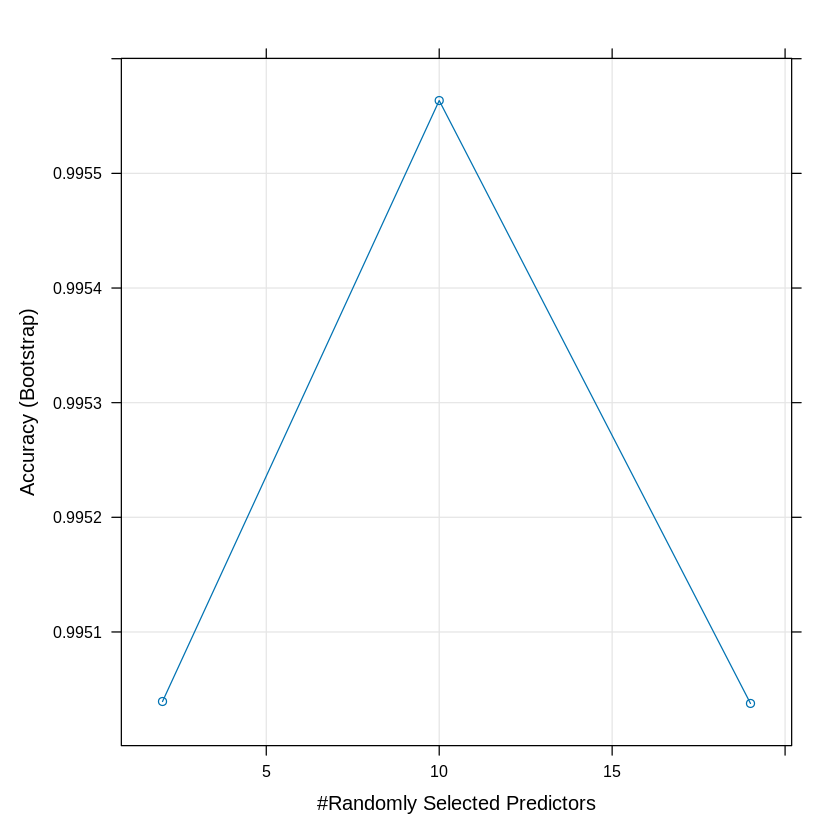

In [ ]:
#rodando RF


model_rf<-train(xtrain,ytrain, method= "rf")

print(model_rf)

plot(model_rf)


#validação cruzada para encontrar os melhores hiperparâmetros
#Validação Cruzada: Considere usar a função train() do pacote caret para realizar validação cruzada e escolher automaticamente os melhores parâmetros do modelo.

In [ ]:
# o melhor subconjunto tem 10 parametros
# a predição será feita com um conjunto de árvores com 10 parametros escolhidas aleatoriamente entre os 19


# predição com o conjunto de teste
pred_rf = predict(model_rf, xtest)


print(confusionMatrix(data = as.factor(pred),reference = as.factor(ytest),positive = '1'))


Confusion Matrix and Statistics

          Reference
Prediction    0    1
         0 1000    1
         1    3  167
                                          
               Accuracy : 0.9966          
                 95% CI : (0.9913, 0.9991)
    No Information Rate : 0.8565          
    P-Value [Acc > NIR] : <2e-16          
                                          
                  Kappa : 0.9862          
                                          
 Mcnemar's Test P-Value : 0.6171          
                                          
            Sensitivity : 0.9940          
            Specificity : 0.9970          
         Pos Pred Value : 0.9824          
         Neg Pred Value : 0.9990          
             Prevalence : 0.1435          
         Detection Rate : 0.1426          
   Detection Prevalence : 0.1452          
      Balanced Accuracy : 0.9955          
                                          
       'Positive' Class : 1               
                        

In [ ]:
#Avalie a importância relativa dos atributos -> Qual parâmetro realmente importa para indicar hazardous ou não?!

install.packages("gbm")
library(gbm)

fitControl <- trainControl(
  method = "repeatedcv",
  number = 3,
  repeats = 3)

grade = expand.grid(n.trees=c(10,100,1000),shrinkage=c(0.01,0.05,0.1,0.5),n.minobsinnode = c(3,5,10),interaction.depth=c(1,5,10))

t0 = Sys.time()
model_gbm<-train(xtrain,ytrain,method='gbm',trControl=fitControl,tuneGrid=grade,verbose = FALSE)
Sys.time() - t0



Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Loaded gbm 2.2.2

This version of gbm is no longer under development. Consider transitioning to gbm3, https://github.com/gbm-developers/gbm3



Time difference of 20.58249 mins

,var,rel.inf
,<chr>,<dbl>
Minimum.Orbit.Intersection,Minimum.Orbit.Intersection,4.531846e+01
Est.Dia.in.KM.max.,Est.Dia.in.KM.max.,4.463326e+01
Absolute.Magnitude,Absolute.Magnitude,9.565240e+00
Mean.Anomaly,Mean.Anomaly,1.237747e-01
Orbit.Uncertainity,Orbit.Uncertainity,1.000667e-01
Jupiter.Tisserand.Invariant,Jupiter.Tisserand.Invariant,4.162396e-02
Perihelion.Distance,Perihelion.Distance,4.119629e-02
Asc.Node.Longitude,Asc.Node.Longitude,3.603023e-02
Aphelion.Dist,Aphelion.Dist,3.075253e-02


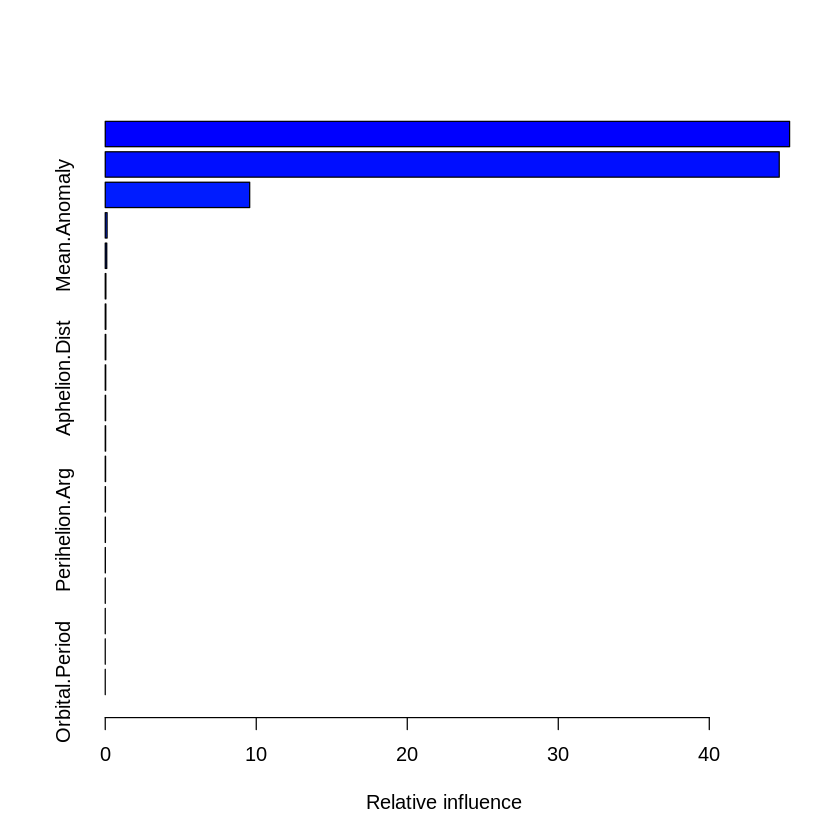

In [ ]:
summary(model_gbm)
